# Análisis meteorológico con Polars

Este notebook resuelve la práctica de meteorología con **Polars** para la carga, limpieza, agregación e integración de datos, y **Matplotlib** para las visualizaciones.

## 1. Exploración inicial

In [ ]:
import polars as pl
import matplotlib.pyplot as plt



estaciones = pl.read_csv( "estaciones.csv")
mediciones = pl.read_csv("mediciones.csv",
    try_parse_dates=True,
)
alertas = pl.read_json("alertas.json").with_columns(
    pl.col("fecha").str.to_date()
)

print("Estaciones:", estaciones.shape)
print("Mediciones:", mediciones.shape)
print("Alertas:", alertas.shape)

Estaciones: (8, 6)
Mediciones: (2880, 8)
Alertas: (12, 6)


In [68]:
print("ESTACIONES")
print("Tipos:", estaciones.dtypes)
print(estaciones.head())
print("Nulos:")
print(estaciones.null_count())

print("\nMEDICIONES")
print("Tipos:", mediciones.dtypes)
print(mediciones.head())
print("Nulos:")
print(mediciones.null_count())

print("\nALERTAS")
print("Tipos:", alertas.dtypes)
print(alertas.head())
print("Nulos:")
print(alertas.null_count())

print("\nESTADÍSTICAS DE LAS MEDICIONES")
print(mediciones.describe())

# Resumen: las mediciones son horarias y las alertas se relacionan con estación y fecha.
# El análisis de nulos de esta sección permite separar ausencia de datos de valores anómalos.

ESTACIONES
Tipos: [String, String, String, Float64, Float64, Int64]
shape: (5, 6)
┌─────────────┬───────────┬─────────────┬─────────┬──────────┬─────────┐
│ id_estacion ┆ nombre    ┆ ciudad      ┆ latitud ┆ longitud ┆ altitud │
│ ---         ┆ ---       ┆ ---         ┆ ---     ┆ ---      ┆ ---     │
│ str         ┆ str       ┆ str         ┆ f64     ┆ f64      ┆ i64     │
╞═════════════╪═══════════╪═════════════╪═════════╪══════════╪═════════╡
│ E001        ┆ Artxanda  ┆ Bilbao      ┆ 43.28   ┆ -2.91    ┆ 312     │
│ E002        ┆ Jaizkibel ┆ Hondarribia ┆ 43.36   ┆ -1.79    ┆ 547     │
│ E003        ┆ Urkiola   ┆ Abadiño     ┆ 43.1    ┆ -2.65    ┆ 720     │
│ E004        ┆ Izki      ┆ Maeztu      ┆ 42.73   ┆ -2.48    ┆ 750     │
│ E005        ┆ Zarautz   ┆ Zarautz     ┆ 43.28   ┆ -2.17    ┆ 15      │
└─────────────┴───────────┴─────────────┴─────────┴──────────┴─────────┘
Nulos:
shape: (1, 6)
┌─────────────┬────────┬────────┬─────────┬──────────┬─────────┐
│ id_estacion ┆ nombre ┆ ciud

## 2. Análisis de las mediciones

Se convierten `fecha` y `hora` a tipos útiles y se crea `hora_num` para ordenar el ciclo diario.

In [81]:
mediciones = mediciones.with_columns(
    pl.col("fecha").cast(pl.Date),
    pl.col("hora").dt.hour().alias("hora_num"),
)

resumen_temperatura = mediciones.select(
    pl.col("temperatura").mean().alias("media_C"),
    pl.col("temperatura").min().alias("minima_C"),
    pl.col("temperatura").max().alias("maxima_C"),
)
print("Temperatura media, mínima y máxima:")
print(resumen_temperatura)

temperatura_horaria = (
    mediciones.group_by("hora_num")
    .agg(
        pl.col("temperatura").mean().alias("temperatura_media"),
        pl.col("temperatura").min().alias("temperatura_minima"),
        pl.col("temperatura").max().alias("temperatura_maxima"),
    )
    .sort("hora_num")
)
print("\nEvolución de la temperatura por hora:")
print(temperatura_horaria)

Temperatura media, mínima y máxima:
shape: (1, 3)
┌──────────┬──────────┬──────────┐
│ media_C  ┆ minima_C ┆ maxima_C │
│ ---      ┆ ---      ┆ ---      │
│ f64      ┆ f64      ┆ f64      │
╞══════════╪══════════╪══════════╡
│ 6.152068 ┆ -3.9     ┆ 48.5     │
└──────────┴──────────┴──────────┘

Evolución de la temperatura por hora:
shape: (8, 4)
┌──────────┬───────────────────┬────────────────────┬────────────────────┐
│ hora_num ┆ temperatura_media ┆ temperatura_minima ┆ temperatura_maxima │
│ ---      ┆ ---               ┆ ---                ┆ ---                │
│ i8       ┆ f64               ┆ f64                ┆ f64                │
╞══════════╪═══════════════════╪════════════════════╪════════════════════╡
│ 0        ┆ 1.105833          ┆ -3.9               ┆ 5.8                │
│ 3        ┆ 2.676389          ┆ -1.7               ┆ 8.5                │
│ 6        ┆ 6.202778          ┆ 1.3                ┆ 12.0               │
│ 9        ┆ 9.608914          ┆ 4.5                

In [70]:
precipitacion_estacion = (
    mediciones.group_by("id_estacion")
    .agg(
        pl.col("precipitacion_mm").sum().alias("precipitacion_total_mm"),
        pl.col("viento_kmh").mean().alias("viento_medio_kmh"),
        pl.col("humedad").mean().alias("humedad_media"),
    )
    .sort("precipitacion_total_mm", descending=True)
)
print("Precipitación acumulada y viento medio por estación:")
print(precipitacion_estacion)
print("\nEstación más lluviosa:", precipitacion_estacion.row(0)[0])
print("Estación con mayor viento medio:", precipitacion_estacion.sort("viento_medio_kmh", descending=True).row(0)[0])

relacion_humedad_lluvia = mediciones.select(
    pl.corr("humedad", "precipitacion_mm").alias("correlacion_humedad_precipitacion")
)
print("\nRelación lineal:")
print(relacion_humedad_lluvia)

viento_extremos = mediciones.select(
    pl.all().sort_by("viento_kmh", descending=True).head(5)
)
print("\nCinco valores más altos de viento:")
print(viento_extremos)

Precipitación acumulada y viento medio por estación:
shape: (8, 4)
┌─────────────┬────────────────────────┬──────────────────┬───────────────┐
│ id_estacion ┆ precipitacion_total_mm ┆ viento_medio_kmh ┆ humedad_media │
│ ---         ┆ ---                    ┆ ---              ┆ ---           │
│ str         ┆ f64                    ┆ f64              ┆ f64           │
╞═════════════╪════════════════════════╪══════════════════╪═══════════════╡
│ E002        ┆ 433.8                  ┆ 15.982778        ┆ 81.976602     │
│ E003        ┆ 401.7                  ┆ 18.236111        ┆ 82.013092     │
│ E005        ┆ 330.7                  ┆ 15.872222        ┆ 82.147911     │
│ E008        ┆ 181.5                  ┆ 15.774444        ┆ 81.756389     │
│ E007        ┆ 177.1                  ┆ 14.078333        ┆ 81.37883      │
│ E004        ┆ 172.9                  ┆ 13.749722        ┆ 81.548056     │
│ E006        ┆ 145.9                  ┆ 17.801667        ┆ 81.234444     │
│ E001        ┆ 126.9

In [71]:
mediciones_join = mediciones.join(estaciones, on="id_estacion", how="left", validate="m:1")
print("Filas tras el JOIN:", mediciones_join.height, "(antes:", mediciones.height, ")")
print("Estaciones sin correspondencia:", mediciones_join.filter(pl.col("nombre").is_null()).height)

altitud_temperatura = (
    mediciones_join.group_by(["id_estacion", "nombre", "ciudad", "altitud"])
    .agg(
        pl.col("temperatura").mean().alias("temperatura_media"),
        pl.col("temperatura").min().alias("temperatura_minima"),
        pl.col("temperatura").max().alias("temperatura_maxima"),
    )
    .sort("altitud")
)
print("\nComparación de estaciones por altitud:")
print(altitud_temperatura)
print("Correlación altitud-temperatura media:", altitud_temperatura.select(pl.corr("altitud", "temperatura_media")))
print("\nTres estaciones comparadas (costa, media y montaña):")
print(altitud_temperatura.filter(pl.col("id_estacion").is_in(["E005", "E001", "E004"])))

Filas tras el JOIN: 2880 (antes: 2880 )
Estaciones sin correspondencia: 0

Comparación de estaciones por altitud:
shape: (8, 7)
┌─────────────┬───────────┬─────────────┬─────────┬────────────────┬───────────────┬───────────────┐
│ id_estacion ┆ nombre    ┆ ciudad      ┆ altitud ┆ temperatura_me ┆ temperatura_m ┆ temperatura_m │
│ ---         ┆ ---       ┆ ---         ┆ ---     ┆ dia            ┆ inima         ┆ axima         │
│ str         ┆ str       ┆ str         ┆ i64     ┆ ---            ┆ ---           ┆ ---           │
│             ┆           ┆             ┆         ┆ f64            ┆ f64           ┆ f64           │
╞═════════════╪═══════════╪═════════════╪═════════╪════════════════╪═══════════════╪═══════════════╡
│ E005        ┆ Zarautz   ┆ Zarautz     ┆ 15      ┆ 8.761003       ┆ 0.2           ┆ 16.8          │
│ E008        ┆ Donostia  ┆ Donostia    ┆ 25      ┆ 8.723333       ┆ 1.3           ┆ 16.5          │
│ E001        ┆ Artxanda  ┆ Bilbao      ┆ 312     ┆ 7.019777    

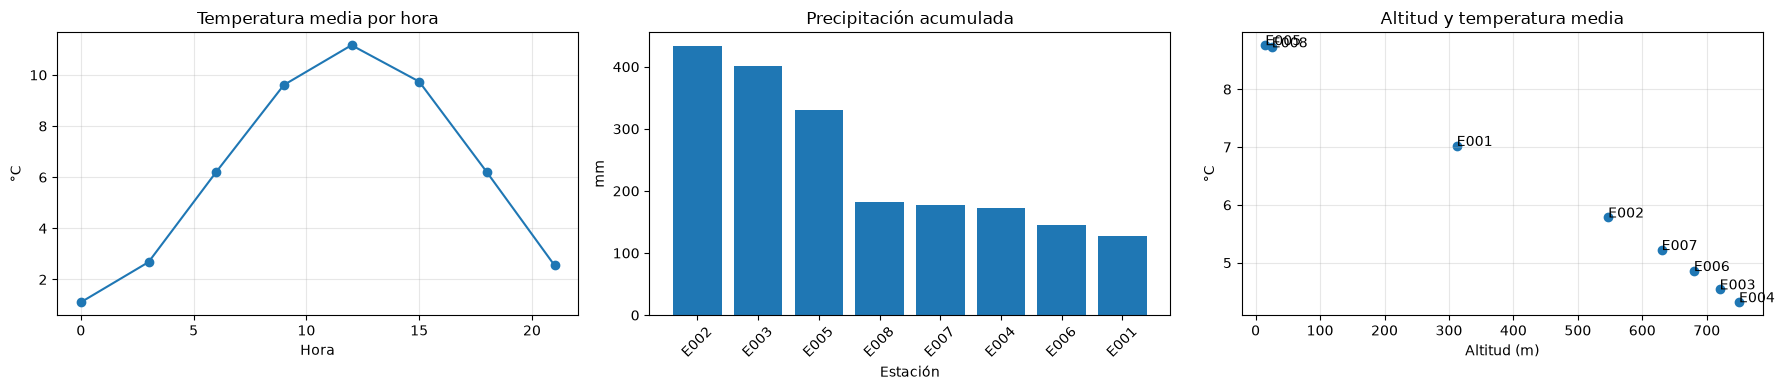

In [72]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(temperatura_horaria["hora_num"], temperatura_horaria["temperatura_media"], marker="o")
axes[0].set(title="Temperatura media por hora", xlabel="Hora", ylabel="°C")
axes[0].grid(alpha=0.3)

axes[1].bar(precipitacion_estacion["id_estacion"], precipitacion_estacion["precipitacion_total_mm"])
axes[1].set(title="Precipitación acumulada", xlabel="Estación", ylabel="mm")
axes[1].tick_params(axis="x", rotation=45)

axes[2].scatter(altitud_temperatura["altitud"], altitud_temperatura["temperatura_media"])
for row in altitud_temperatura.iter_rows(named=True):
    axes[2].annotate(row["id_estacion"], (row["altitud"], row["temperatura_media"]))
axes[2].set(title="Altitud y temperatura media", xlabel="Altitud (m)", ylabel="°C")
axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Calidad de los datos

Se consideran sospechosas las temperaturas inferiores a -30 °C o superiores a 50 °C, humedades fuera de `[0, 100]` y velocidades de viento negativas. Los registros se reportan, no se eliminan automáticamente.

In [73]:
problemas = {
    "temperaturas_sospechosas": mediciones.filter((pl.col("temperatura") < -30) | (pl.col("temperatura") > 50)),
    "humedades_fuera_de_rango": mediciones.filter((pl.col("humedad") < 0) | (pl.col("humedad") > 100)),
    "viento_negativo": mediciones.filter(pl.col("viento_kmh") < 0),
}
print("Nulos por columna en mediciones:")
print(mediciones.null_count())
for nombre, registros in problemas.items():
    print(f"\n{nombre}: {registros.height} registros")
    print(registros.head(10))

print("\nResumen de calidad:")
print({nombre: registros.height for nombre, registros in problemas.items()})


Nulos por columna en mediciones:
shape: (1, 9)
┌─────────────┬───────┬──────┬─────────────┬───┬────────────┬─────────────┬─────────────┬──────────┐
│ id_estacion ┆ fecha ┆ hora ┆ temperatura ┆ … ┆ viento_kmh ┆ precipitaci ┆ presion_hpa ┆ hora_num │
│ ---         ┆ ---   ┆ ---  ┆ ---         ┆   ┆ ---        ┆ on_mm       ┆ ---         ┆ ---      │
│ u32         ┆ u32   ┆ u32  ┆ u32         ┆   ┆ u32        ┆ ---         ┆ u32         ┆ u32      │
│             ┆       ┆      ┆             ┆   ┆            ┆ u32         ┆             ┆          │
╞═════════════╪═══════╪══════╪═════════════╪═══╪════════════╪═════════════╪═════════════╪══════════╡
│ 0           ┆ 0     ┆ 0    ┆ 3           ┆ … ┆ 0          ┆ 0           ┆ 0           ┆ 0        │
└─────────────┴───────┴──────┴─────────────┴───┴────────────┴─────────────┴─────────────┴──────────┘

temperaturas_sospechosas: 0 registros
shape: (0, 9)
┌─────────────┬───────┬──────┬─────────────┬───┬────────────┬─────────────┬─────────────┬───

## 4. Integración con alertas

In [74]:
alertas_estaciones = alertas.join(
    estaciones.select(["id_estacion", "nombre", "ciudad", "altitud"]),
    on="id_estacion",
    how="left",
    validate="m:1",
)
alertas_mediciones = alertas_estaciones.join(
    mediciones_join,
    on=["id_estacion", "fecha"],
    how="left",
    suffix="_medicion",
)
print("Alertas con estación:")
print(alertas_estaciones)
print("\nNúmero de alertas por estación:")
print(alertas_estaciones.group_by(["id_estacion", "nombre"]).len().sort("len", descending=True))
print("\nNúmero de alertas por tipo:")
print(alertas_estaciones.group_by("tipo").len().sort("len", descending=True))
print("\nFechas y estaciones asociadas a alertas:")
print(alertas_estaciones.select(["fecha", "id_estacion", "nombre", "tipo", "nivel"]).sort("fecha"))
print("Filas de alertas con mediciones coincidentes:", alertas_mediciones.filter(pl.col("temperatura").is_not_null()).height)

Alertas con estación:
shape: (12, 9)
┌───────────┬────────────┬────────────┬────────┬───┬────────────┬───────────┬────────────┬─────────┐
│ id_alerta ┆ id_estacio ┆ fecha      ┆ tipo   ┆ … ┆ descripcio ┆ nombre    ┆ ciudad     ┆ altitud │
│ ---       ┆ n          ┆ ---        ┆ ---    ┆   ┆ n          ┆ ---       ┆ ---        ┆ ---     │
│ str       ┆ ---        ┆ date       ┆ str    ┆   ┆ ---        ┆ str       ┆ str        ┆ i64     │
│           ┆ str        ┆            ┆        ┆   ┆ str        ┆           ┆            ┆         │
╞═══════════╪════════════╪════════════╪════════╪═══╪════════════╪═══════════╪════════════╪═════════╡
│ A001      ┆ E001       ┆ 2026-01-07 ┆ Viento ┆ … ┆ Rachas de  ┆ Artxanda  ┆ Bilbao     ┆ 312     │
│           ┆            ┆            ┆        ┆   ┆ viento     ┆           ┆            ┆         │
│           ┆            ┆            ┆        ┆   ┆ superiores ┆           ┆            ┆         │
│           ┆            ┆            ┆        ┆   ┆ a

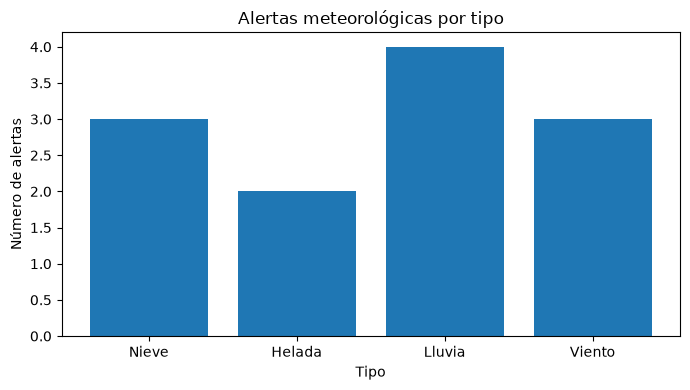

In [75]:
alerta_resumen = alertas_estaciones.group_by("tipo").agg(
    pl.len().alias("alertas"),
    pl.col("altitud").mean().alias("altitud_media"),
)
alerta_resumen.plot if False else None
plt.figure(figsize=(7, 4))
plt.bar(alerta_resumen["tipo"], alerta_resumen["alertas"])
plt.title("Alertas meteorológicas por tipo")
plt.xlabel("Tipo")
plt.ylabel("Número de alertas")
plt.tight_layout()
plt.show()

## 5. Investigación abierta

Las siguientes cinco preguntas reutilizan las tablas preparadas y muestran código, resultado y conclusión.

In [76]:
dia_mas_lluvioso = (mediciones.group_by("fecha").agg(pl.col("precipitacion_mm").sum().alias("lluvia_mm")).sort("lluvia_mm", descending=True).head(1))
print("Día más lluvioso:", dia_mas_lluvioso)
print("Conclusión: este día concentra la mayor precipitación acumulada del periodo.")



Día más lluvioso: shape: (1, 2)
┌────────────┬───────────┐
│ fecha      ┆ lluvia_mm │
│ ---        ┆ ---       │
│ date       ┆ f64       │
╞════════════╪═══════════╡
│ 2026-01-12 ┆ 84.7      │
└────────────┴───────────┘
Conclusión: este día concentra la mayor precipitación acumulada del periodo.


In [77]:
minimo = mediciones.sort("temperatura").select(["id_estacion", "fecha", "hora", "temperatura"]).head(1)
print("\n Temperatura mínima:", minimo)
print("Conclusión: el mínimo aparece en la estación y momento indicados; es un episodio potencial de helada.")




 Temperatura mínima: shape: (1, 4)
┌─────────────┬────────────┬──────────┬─────────────┐
│ id_estacion ┆ fecha      ┆ hora     ┆ temperatura │
│ ---         ┆ ---        ┆ ---      ┆ ---         │
│ str         ┆ date       ┆ time     ┆ f64         │
╞═════════════╪════════════╪══════════╪═════════════╡
│ E001        ┆ 2026-01-20 ┆ 09:00:00 ┆ null        │
└─────────────┴────────────┴──────────┴─────────────┘
Conclusión: el mínimo aparece en la estación y momento indicados; es un episodio potencial de helada.


In [78]:
horas_lluvia = (mediciones.filter(pl.col("precipitacion_mm") > 0).group_by("id_estacion").len().sort("len", descending=True).head(1))
print("\n Estación con más horas de lluvia:", horas_lluvia)
print("Conclusión: se compara frecuencia de horas lluviosas, no solo milímetros acumulados.")



 Estación con más horas de lluvia: shape: (1, 2)
┌─────────────┬─────┐
│ id_estacion ┆ len │
│ ---         ┆ --- │
│ str         ┆ u32 │
╞═════════════╪═════╡
│ E002        ┆ 86  │
└─────────────┴─────┘
Conclusión: se compara frecuencia de horas lluviosas, no solo milímetros acumulados.


In [79]:

max_viento = mediciones.sort("viento_kmh", descending=True).select(["id_estacion", "fecha", "hora", "viento_kmh"]).head(1)
print("\n Viento máximo:", max_viento)
print("Conclusión: este registro identifica la condición más extrema de viento observada.")




 Viento máximo: shape: (1, 4)
┌─────────────┬────────────┬──────────┬────────────┐
│ id_estacion ┆ fecha      ┆ hora     ┆ viento_kmh │
│ ---         ┆ ---        ┆ ---      ┆ ---        │
│ str         ┆ date       ┆ time     ┆ f64        │
╞═════════════╪════════════╪══════════╪════════════╡
│ E006        ┆ 2026-02-14 ┆ 12:00:00 ┆ 35.6       │
└─────────────┴────────────┴──────────┴────────────┘
Conclusión: este registro identifica la condición más extrema de viento observada.


In [80]:
comparacion = altitud_temperatura.filter(pl.col("id_estacion").is_in(["E005", "E008", "E003", "E004"])).select(["id_estacion", "altitud", "temperatura_media"])
print("\n Costa frente a montaña:\n", comparacion)
print("Conclusión: la tabla permite comprobar si la temperatura media disminuye al aumentar la altitud; la correlación calculada arriba cuantifica la tendencia global.")


 Costa frente a montaña:
 shape: (4, 3)
┌─────────────┬─────────┬───────────────────┐
│ id_estacion ┆ altitud ┆ temperatura_media │
│ ---         ┆ ---     ┆ ---               │
│ str         ┆ i64     ┆ f64               │
╞═════════════╪═════════╪═══════════════════╡
│ E005        ┆ 15      ┆ 8.761003          │
│ E008        ┆ 25      ┆ 8.723333          │
│ E003        ┆ 720     ┆ 4.539833          │
│ E004        ┆ 750     ┆ 4.317778          │
└─────────────┴─────────┴───────────────────┘
Conclusión: la tabla permite comprobar si la temperatura media disminuye al aumentar la altitud; la correlación calculada arriba cuantifica la tendencia global.


## Conclusiones

- Las agregaciones por hora permiten describir el ciclo diario de temperatura.
- Las agrupaciones por estación separan precipitación acumulada, viento medio y humedad media.
- El JOIN de mediciones con estaciones conserva todas las mediciones y añade ubicación y altitud; validate="m:1" comprueba que cada estación sea única.
- Los controles de calidad distinguen nulos de valores fuera de rango y dejan los registros problemáticos disponibles para su revisión.
- La integración con alertas permite estudiar conjuntamente fecha, estación, tipo, nivel y condiciones observadas.